# MNIST ile MLP Tabanlı El Yazısı Rakam Tanıma

CNN yok, hazır model yok; model sıfırdan eğitilir. Bu notebook `mnist_mlp.py` ve `predict_digits.py` ile aynı kodu içerir; hücreler sırayla çalıştırılabilir (seed sabit).

## 1. Kurulum ve veri bölme
60k MNIST train → **50k train + 10k validation** (seed 42). 10k test seti seçimde kullanılmaz, yalnızca en sonda bir kez.

In [1]:
import json, time
from pathlib import Path
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import datasets
%matplotlib inline

SEED = 42
VAL_SIZE = 10_000
MEAN, STD = 0.1307, 0.3081   # MNIST train istatistikleri
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)
device = torch.device("cpu")

In [2]:
def load_data():
    tr = datasets.MNIST("data", train=True, download=True)
    te = datasets.MNIST("data", train=False, download=True)

    def prep(ds):
        x = ds.data.float().div(255).sub(MEAN).div(STD).view(len(ds), -1)  # 28x28 -> 784
        return x, ds.targets

    x, y = prep(tr)
    x_te, y_te = prep(te)
    g = torch.Generator().manual_seed(SEED)
    perm = torch.randperm(len(x), generator=g)
    val_idx, tr_idx = perm[:VAL_SIZE], perm[VAL_SIZE:]
    return (x[tr_idx], y[tr_idx]), (x[val_idx], y[val_idx]), (x_te, y_te)


def make_mlp(hidden, dropout=0.0):
    layers, d = [], 784
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU()]
        if dropout > 0:
            layers.append(nn.Dropout(dropout))
        d = h
    layers.append(nn.Linear(d, 10))  # logits; softmax CrossEntropyLoss icinde
    return nn.Sequential(*layers)


@torch.no_grad()
def evaluate(model, x, y, loss_fn, bs=2000):
    model.eval()
    tot_loss, correct = 0.0, 0
    for i in range(0, len(x), bs):
        out = model(x[i:i + bs])
        tot_loss += loss_fn(out, y[i:i + bs]).item() * len(out)
        correct += (out.argmax(1) == y[i:i + bs]).sum().item()
    return tot_loss / len(x), correct / len(x)


def run(cfg, train, val):
    torch.manual_seed(SEED)
    model = make_mlp(cfg["hidden"], cfg.get("dropout", 0.0)).to(device)
    loss_fn = nn.CrossEntropyLoss()
    if cfg["optimizer"] == "adam":
        opt = torch.optim.Adam(model.parameters(), lr=cfg["lr"])
    else:
        opt = torch.optim.SGD(model.parameters(), lr=cfg["lr"], momentum=cfg.get("momentum", 0.0))

    x_tr, y_tr = train
    hist = {k: [] for k in ("train_loss", "val_loss", "train_acc", "val_acc")}
    g = torch.Generator().manual_seed(SEED)
    t0 = time.time()
    for ep in range(cfg["epochs"]):
        model.train()
        perm = torch.randperm(len(x_tr), generator=g)
        for i in range(0, len(x_tr), cfg["batch_size"]):
            idx = perm[i:i + cfg["batch_size"]]
            opt.zero_grad()
            loss_fn(model(x_tr[idx]), y_tr[idx]).backward()
            opt.step()
        # epoch sonu metrikleri (train metrigi eval modunda, tum train seti uzerinde)
        tl, ta = evaluate(model, *train, loss_fn)
        vl, va = evaluate(model, *val, loss_fn)
        for k, v in zip(hist, (tl, vl, ta, va)):
            hist[k].append(v)
        print(f"  [{cfg['name']}] ep {ep + 1:2d}/{cfg['epochs']}  "
              f"train {tl:.4f}/{ta:.4f}  val {vl:.4f}/{va:.4f}")
    return model, hist, time.time() - t0


def plot_history(hist, title, path):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(ep, hist["train_loss"], label="train")
    ax[0].plot(ep, hist["val_loss"], label="validation")
    ax[0].set(title=f"{title} - Loss", xlabel="epoch", ylabel="CrossEntropy loss")
    ax[1].plot(ep, hist["train_acc"], label="train")
    ax[1].plot(ep, hist["val_acc"], label="validation")
    ax[1].set(title=f"{title} - Accuracy", xlabel="epoch", ylabel="accuracy")
    for a in ax:
        a.grid(alpha=.3)
        a.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()

In [3]:
train, val, test = load_data()
print(f'train {len(train[0])} | val {len(val[0])} | test {len(test[0])}')
loss_fn = nn.CrossEntropyLoss()

train 50000 | val 10000 | test 10000


## 2. Deney 1 – Temel MLP
784 → 256 → ReLU → 128 → ReLU → 10 · CrossEntropyLoss · Adam (lr=1e-3) · batch 128 · 15 epoch

In [4]:
CONFIGS = [
    dict(name="baseline", hidden=[256, 128], optimizer="adam", lr=1e-3, batch_size=128, epochs=15),
    dict(name="kucuk_agi", hidden=[64, 32], optimizer="adam", lr=1e-3, batch_size=128, epochs=15),
    dict(name="buyuk_ag", hidden=[512, 256, 128], optimizer="adam", lr=1e-3, batch_size=128, epochs=15),
    dict(name="yuksek_lr", hidden=[256, 128], optimizer="adam", lr=1e-2, batch_size=128, epochs=15),
    dict(name="sgd_momentum", hidden=[256, 128], optimizer="sgd", lr=0.05, momentum=0.9, batch_size=128, epochs=15),
    dict(name="dropout0.3", hidden=[256, 128], optimizer="adam", lr=1e-3, batch_size=128, epochs=15, dropout=0.3),
]
models, hists, secs = {}, {}, {}
cfg = CONFIGS[0]
models[cfg["name"]], hists[cfg["name"]], secs[cfg["name"]] = run(cfg, train, val)
h = hists["baseline"]
print(f"\nTraining loss {h['train_loss'][-1]:.4f} | Validation loss {h['val_loss'][-1]:.4f}")
print(f"Training acc {h['train_acc'][-1]:.4f} | Validation acc {h['val_acc'][-1]:.4f} | Süre {secs['baseline']:.1f} sn")

  [baseline] ep  1/15  train 0.1304/0.9620  val 0.1437/0.9585


  [baseline] ep  2/15  train 0.0807/0.9758  val 0.1056/0.9662


  [baseline] ep  3/15  train 0.0654/0.9798  val 0.0992/0.9686


  [baseline] ep  4/15  train 0.0512/0.9839  val 0.0992/0.9703


  [baseline] ep  5/15  train 0.0355/0.9885  val 0.0893/0.9744


...

  [baseline] ep 11/15  train 0.0164/0.9945  val 0.1078/0.9747


  [baseline] ep 12/15  train 0.0106/0.9959  val 0.0970/0.9760


  [baseline] ep 13/15  train 0.0129/0.9954  val 0.0996/0.9767


  [baseline] ep 14/15  train 0.0135/0.9954  val 0.1035/0.9779


  [baseline] ep 15/15  train 0.0087/0.9970  val 0.0985/0.9784

Training loss 0.0087 | Validation loss 0.0985
Training acc 0.9970 | Validation acc 0.9784 | Süre 4.1 sn


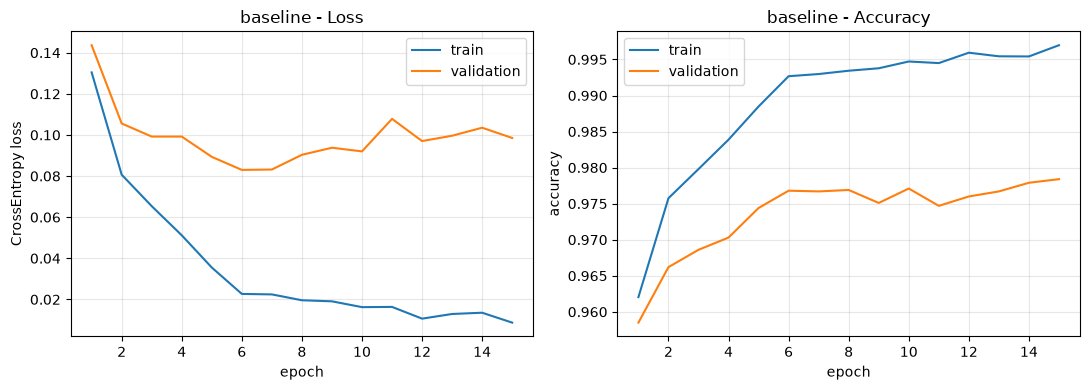

In [5]:
plot_history(hists["baseline"], "baseline", OUT / "curves_baseline.png")

## 3. Hiperparametre karşılaştırması
Aynı seed ve bölme; seçim **yalnızca validation**'a göre.


== kucuk_agi


  [kucuk_agi] ep  1/15  train 0.2150/0.9382  val 0.2248/0.9339


  [kucuk_agi] ep  2/15  train 0.1518/0.9568  val 0.1689/0.9485


  [kucuk_agi] ep  3/15  train 0.1182/0.9651  val 0.1441/0.9564


  [kucuk_agi] ep  4/15  train 0.0907/0.9735  val 0.1223/0.9620


...

  [dropout0.3] ep 11/15  train 0.0202/0.9936  val 0.0762/0.9784


  [dropout0.3] ep 12/15  train 0.0195/0.9940  val 0.0800/0.9781


  [dropout0.3] ep 13/15  train 0.0143/0.9959  val 0.0690/0.9804


  [dropout0.3] ep 14/15  train 0.0154/0.9953  val 0.0720/0.9812


  [dropout0.3] ep 15/15  train 0.0144/0.9956  val 0.0719/0.9790


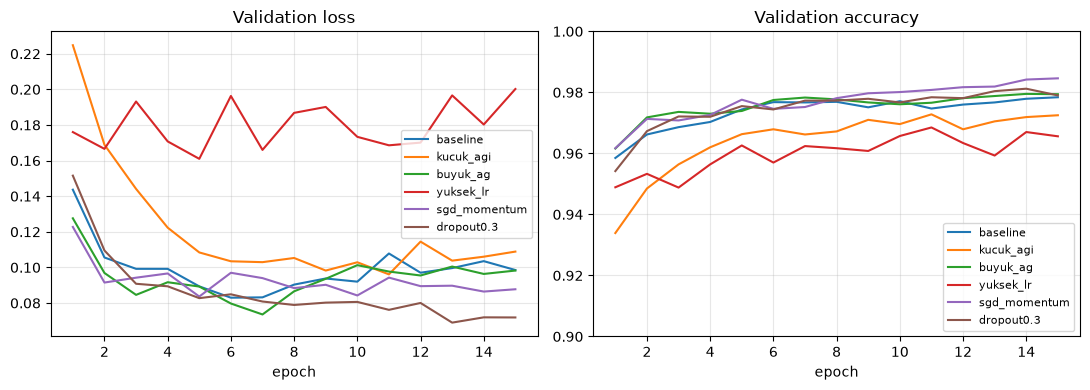

En iyi (validation): sgd_momentum
config          tr_loss val_loss  tr_acc val_acc  sure(s)
baseline         0.0087   0.0985  0.9970  0.9784      4.1
kucuk_agi        0.0246   0.1089  0.9920  0.9725      2.4
buyuk_ag         0.0094   0.0982  0.9968  0.9794      7.8
yuksek_lr        0.0757   0.2002  0.9811  0.9656      3.8
sgd_momentum     0.0002   0.0877  1.0000  0.9846      2.6
dropout0.3       0.0144   0.0719  0.9956  0.9790      4.2


In [6]:
for cfg in CONFIGS[1:]:
    print(f"\n== {cfg['name']}")
    models[cfg["name"]], hists[cfg["name"]], secs[cfg["name"]] = run(cfg, train, val)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for n, hh in hists.items():
    ax[0].plot(range(1, 16), hh["val_loss"], label=n); ax[1].plot(range(1, 16), hh["val_acc"], label=n)
ax[0].set(title="Validation loss", xlabel="epoch"); ax[1].set(title="Validation accuracy", xlabel="epoch", ylim=(0.9, 1.0))
for a in ax: a.grid(alpha=.3); a.legend(fontsize=8)
fig.tight_layout(); fig.savefig(OUT / "comparison_val.png", dpi=130); plt.show()

best = max(hists, key=lambda n: hists[n]["val_acc"][-1])
print("En iyi (validation):", best)
print(f"{'config':14s} {'tr_loss':>8s} {'val_loss':>8s} {'tr_acc':>7s} {'val_acc':>7s} {'sure(s)':>8s}")
for n, hh in hists.items():
    print(f"{n:14s} {hh['train_loss'][-1]:8.4f} {hh['val_loss'][-1]:8.4f} {hh['train_acc'][-1]:7.4f} {hh['val_acc'][-1]:7.4f} {secs[n]:8.1f}")

## 4. Test (yalnızca baseline + validation'ın seçtiği model, bir kez)

In [7]:
for n in ("baseline", best):
    print(f"{n}: test acc = {evaluate(models[n], *test, loss_fn)[1]:.4f}")

baseline: test acc = 0.9792
sgd_momentum: test acc = 0.9826


## 5. Kendi el yazım – okul numarası
iPad'de Apple Pencil ile yazıldı (`my_digits/numara.jpg`). Önişleme: gri ton → renk tersleme (MNIST: siyah zemin/beyaz rakam) → rakamları ayırma → 20×20'ye sığdırma → ağırlık merkezine göre 28×28 ortalama → MNIST normalizasyonu.

In [8]:
def to_mnist_gray(path):
    """Gri ton, [0,255], zemin siyah (0) rakam beyaz (255)."""
    img = Image.open(path)
    if img.mode in ("RGBA", "LA"):  # seffaf PNG'leri beyaz zemine yapistir
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(bg, img.convert("RGBA"))
    a = np.asarray(img.convert("L"), dtype=np.float32)
    # Zemin = kenar piksellerinin medyani; aciksa (kagit/beyaz tuval) ters cevir
    border = np.concatenate([a[0], a[-1], a[:, 0], a[:, -1]])
    if np.median(border) > 127:
        a = 255 - a
    a -= a.min()
    if a.max() > 0:
        a *= 255 / a.max()
    return a


def split_digits(a, min_gap=None):
    """Sutun projeksiyonu ile rakamlari ayirir; (x0, x1) listesi doner."""
    mask = a > 0.25 * 255
    cols = mask.any(axis=0)
    h, w = a.shape
    min_gap = min_gap or max(3, w // 100)
    segs, start, gap = [], None, 0
    for x in range(w):
        if cols[x]:
            if start is None:
                start = x
            gap = 0
        elif start is not None:
            gap += 1
            if gap >= min_gap:
                segs.append((start, x - gap + 1))
                start, gap = None, 0
    if start is not None:
        segs.append((start, w))
    return segs


def force_split(a, segs, n):
    """Birbirine degen rakamlar tek parca gelirse: en genis parcayi, sutun murekkebinin
    en az oldugu noktadan (orta %30-70 bandinda) bolerek toplam n rakama tamamla."""
    ink = (a > 0.25 * 255).sum(axis=0)
    segs = list(segs)
    while len(segs) < n:
        i = max(range(len(segs)), key=lambda k: segs[k][1] - segs[k][0])
        x0, x1 = segs[i]
        lo, hi = x0 + int(0.3 * (x1 - x0)), x0 + int(0.7 * (x1 - x0))
        cut = lo + int(np.argmin(ink[lo:hi + 1]))
        segs[i:i + 1] = [(x0, cut), (cut, x1)]
    return segs


def digit_to_28(a, x0, x1):
    """Tek rakami MNIST gibi 20x20 kutuya sigdirip agirlik merkeziyle 28x28'e ortalar."""
    mask = a[:, x0:x1] > 0.25 * 255
    ys = np.where(mask.any(axis=1))[0]
    crop = a[ys[0]:ys[-1] + 1, x0:x1]
    h, w = crop.shape
    s = 20 / max(h, w)
    nh, nw = max(1, round(h * s)), max(1, round(w * s))
    small = np.asarray(Image.fromarray(crop.astype(np.uint8)).resize((nw, nh), Image.LANCZOS), dtype=np.float32)
    canvas = np.zeros((28, 28), dtype=np.float32)
    canvas[(28 - nh) // 2:(28 - nh) // 2 + nh, (28 - nw) // 2:(28 - nw) // 2 + nw] = small
    # agirlik merkezini 14,14'e kaydir (MNIST ayni sekilde ortalanmis)
    tot = canvas.sum()
    if tot > 0:
        cy = (canvas.sum(1) * np.arange(28)).sum() / tot
        cx = (canvas.sum(0) * np.arange(28)).sum() / tot
        dy, dx = int(round(14 - cy)), int(round(14 - cx))
        canvas = np.roll(canvas, (dy, dx), axis=(0, 1))
    return canvas

8 parça bulundu


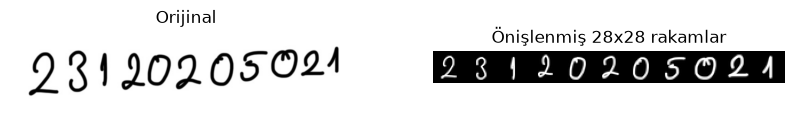

baseline       tahmin: 23120205021 | gerçek: 23120205021 | doğruluk: 100%
  güven: 0.91 0.95 1.00 0.98 1.00 1.00 1.00 1.00 1.00 1.00 0.86
sgd_momentum   tahmin: 23120205021 | gerçek: 23120205021 | doğruluk: 100%
  güven: 1.00 0.99 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00 1.00


In [9]:
LABEL = "23120205021"
a = to_mnist_gray("my_digits/numara.jpg")
segs = split_digits(a)
print(len(segs), "parça bulundu")
if len(segs) < len(LABEL):   # birbirine değen rakamlar: beklenen rakam SAYISINA göre böl
    segs = force_split(a, segs, len(LABEL))
digits = np.stack([digit_to_28(a, x0, x1) for x0, x1 in segs])
x = torch.from_numpy(digits / 255.0).float().sub(MEAN).div(STD).view(len(digits), -1)

fig, ax = plt.subplots(1, 2, figsize=(10, 2.2))
ax[0].imshow(Image.open("my_digits/numara.jpg")); ax[0].axis("off"); ax[0].set_title("Orijinal")
ax[1].imshow(np.concatenate(list(digits), axis=1), cmap="gray"); ax[1].axis("off"); ax[1].set_title("Önişlenmiş 28x28 rakamlar")
plt.show()

for n in ("baseline", best):
    models[n].eval()
    with torch.no_grad():
        p = torch.softmax(models[n](x), 1)
    pred = "".join(map(str, p.argmax(1).tolist()))
    acc = np.mean([c == d for c, d in zip(LABEL, pred)])
    print(f"{n:14s} tahmin: {pred} | gerçek: {LABEL} | doğruluk: {acc:.0%}")
    print("  güven:", " ".join(f"{c:.2f}" for c in p.max(1).values))

## 6. Değerlendirme
- MNIST test accuracy ≈ %98; kendi numaramda 11/11. Ancak **11 rakam çok küçük bir örneklem**, bu "gerçek dünyada daha iyi" anlamına gelmez.
- Başarının büyük kısmı önişlemeden gelir (kalın kalem, temiz zemin, ortalama, 20×20 ölçekleme). Bu adımlar olmadan MNIST'ten farklı dağılım (distribution shift) nedeniyle düşüş beklenir.
- Birbirine değen rakamlar otomatik ayrılamadı; beklenen rakam **sayısı** (değerleri değil) kullanılarak bölündü.
- Tüm configlerde train acc > val acc: MLP 15 epoch'ta train setini neredeyse ezberliyor (overfitting). Tek seed ile ~%0.1'lik farklar gürültü sınırında.

Ayrıntılı tablo ve yorum: `README.md`.